In [ ]:
import torch, torchvision, cv2, numpy as np
from tqdm.auto import tqdm
from google.colab import files
from google.colab.patches import cv2_imshow

device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch:", torch.__version__, "| device:", device)

torch: 2.11.0+cu130 | device: cuda


In [ ]:
#loading model deeplabV3
from torchvision.models.segmentation import deeplabv3_resnet101, DeepLabV3_ResNet101_Weights

weights = DeepLabV3_ResNet101_Weights.DEFAULT
model = deeplabv3_resnet101(weights=weights).to(device).eval()

PERSON = weights.meta["categories"].index("person")
print("person class index:", PERSON)

Downloading: "https://download.pytorch.org/models/deeplabv3_resnet101_coco-586e9e4e.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet101_coco-586e9e4e.pth


100%|██████████| 233M/233M [00:01<00:00, 175MB/s]


person class index: 15


DeeplabV3 is pretrained on a COCO subset using the 21 Pascal VOC classes.
.eval() turns off dropout and batch-norm updates. Forgetting it gives noisy, inconsistent predictions.


In [ ]:
up = files.upload()
img_path = next(iter(up))
img_bgr = cv2.imread(img_path)
print(img_path, img_bgr.shape)   # (height, width, 3)

Saving sample_street_pictures.jpg to sample_street_pictures.jpg
sample_street_pictures.jpg (950, 1300, 3)


In [ ]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

@torch.no_grad()
def person_alpha(frame_bgr, size=520):
    h, w = frame_bgr.shape[:2]
    rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

    # Resize so the longer side equals `size`
    scale = size / max(h, w)
    small = cv2.resize(rgb, (round(w * scale), round(h * scale)), interpolation=cv2.INTER_AREA)

    # To tensor [1, 3, H, W], scale to 0-1, normalize
    x = torch.from_numpy(small).to(device).permute(2, 0, 1).unsqueeze(0).float() / 255
    x = (x - MEAN) / STD

    logits = model(x)["out"]                 # [1, 21, h', w']
    prob = logits.softmax(1)[0, PERSON]      # person probability per pixel, [h', w']

    # Back to the original resolution
    prob = torch.nn.functional.interpolate(
        prob[None, None], size=(h, w), mode="bilinear", align_corners=False)[0, 0]
    return prob.cpu().numpy()                # float array in [0, 1]

Normalization: the backbone was trained on ImageNet-normalized inputs, so we must use the same mean and std.
Resizing to ~520 px: the model runs faster and works well at this scale. The prediction is then upsampled back to full resolution.
Softmax across classes, then pick the person channel: this gives a probability from 0 to 1 per pixel instead of the usual argmax hard label. That’s the key trick, because a soft value at boundaries (0.4, 0.7) gives natural edge blending.
@torch.no_grad() skips gradient tracking, which saves memory and time at inference.
The output is the same size as the input, so it plugs straight into compositing.

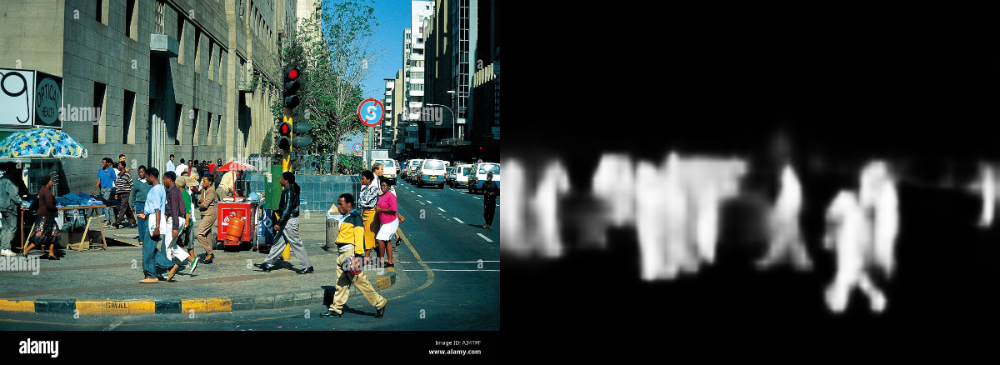

In [ ]:
def show(img, width=800):
    h, w = img.shape[:2]
    cv2_imshow(cv2.resize(img, (width, round(h * width / w))))

alpha = person_alpha(img_bgr)
alpha_vis = cv2.cvtColor((alpha * 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)
show(np.hstack([img_bgr, alpha_vis]), width=1200)

We multiply the alpha by 255 to display it as a grayscale image (white means person, black means background), then convert to 3 channels so we can hstack it next to the original.

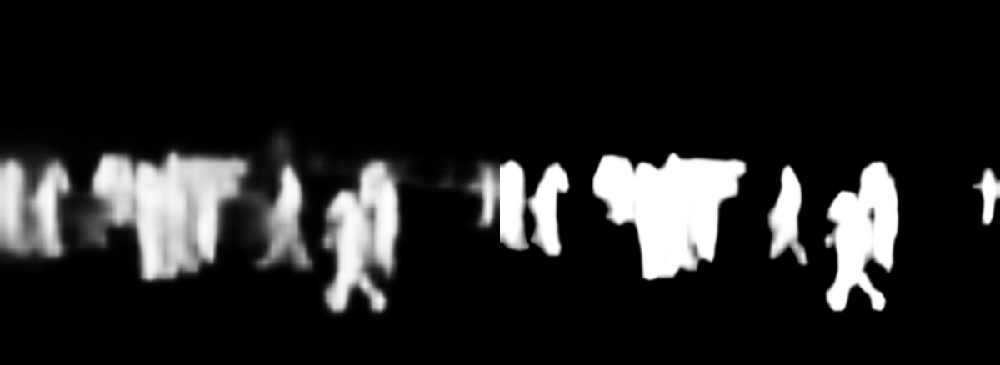

In [ ]:
def refine(alpha, lo=0.3, hi=0.7, min_area_frac=0.002, feather=2):
    # 1. Contrast stretch: below lo -> 0, above hi -> 1, smooth in between
    a = np.clip((alpha - lo) / (hi - lo), 0, 1)
    a = a * a * (3 - 2 * a)                     # smoothstep curve

    # 2. Remove tiny disconnected blobs
    binary = (a > 0.5).astype(np.uint8)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)
    keep = np.zeros_like(binary)
    min_area = min_area_frac * a.size
    for i in range(1, n):                        # label 0 is background
        if stats[i, cv2.CC_STAT_AREA] >= min_area:
            keep[labels == i] = 1
    keep = cv2.dilate(keep, np.ones((9, 9), np.uint8))   # protect soft edges near kept regions
    a = a * keep

    # 3. Feather the edges slightly
    if feather > 0:
        a = cv2.GaussianBlur(a.astype(np.float32), (0, 0), feather)
    return np.clip(a, 0, 1)

alpha_ref = refine(alpha)
show(np.hstack([alpha_vis,
                cv2.cvtColor((alpha_ref * 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)]), width=1200)

Step 1, contrast stretch: raw probabilities hover around 0.2 to 0.8 near edges. We map anything below 0.3 to 0 and above 0.7 to 1, and the smoothstep curve (3a² − 2a³) blends the middle without hard jumps. Tune lo and hi to taste.
Step 2, blob removal: connectedComponentsWithStats labels each connected region and reports its area. Tiny false-positive patches (below 0.2% of the image) are dropped. We use an area threshold rather than “keep the largest component” so that multiple people still work.
Dilation before multiplying: without it, the soft edge pixels just outside the binary mask would be zeroed, giving a harsh cut.
Step 3, feathering: a light Gaussian blur makes the final cutout edge look natural.
Compare the left (raw) and right (refined) images. If it eats thin details like hair, move lo and hi closer together or lower min_area_frac

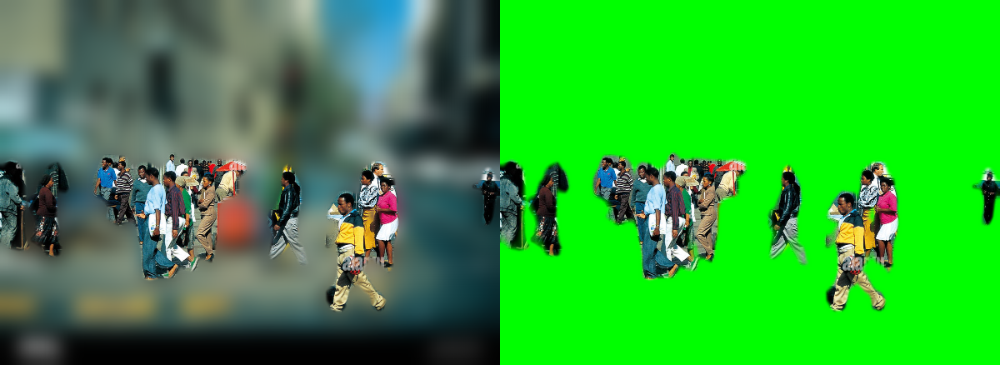

In [ ]:
def replace_background(frame, alpha, mode="blur", bg=None, color=(0, 255, 0)):
    h, w = frame.shape[:2]
    if mode == "blur":
        background = cv2.GaussianBlur(frame, (0, 0), 25)
    elif mode == "color":
        background = np.full_like(frame, color)          # BGR color
    elif mode == "image":
        background = cv2.resize(bg, (w, h))
    else:
        raise ValueError("mode must be 'blur', 'color' or 'image'")

    a = alpha[..., None]                                  # [H, W, 1] to broadcast over channels
    out = a * frame.astype(np.float32) + (1 - a) * background.astype(np.float32)
    return out.astype(np.uint8)

results = [replace_background(img_bgr, alpha_ref, "blur"),
           replace_background(img_bgr, alpha_ref, "color", color=(0, 255, 0))]
show(np.hstack(results), width=1200)

The core formula is alpha compositing: output = α · foreground + (1 − α) · background. Where α = 1 you see the person, where α = 0 you see the new background, and in between you get a smooth blend.
alpha[..., None] adds a channel axis so one alpha value multiplies all three color channels.
We convert to float32 before blending, because multiplying uint8 arrays by fractions would overflow or truncate, then cast back at the end.
Blur mode (like a video-call “portrait” effect) and solid color mode (a green screen) are shown side by side. For a custom background, load an image with cv2.imread and pass mode="image", bg=that_image.


In [1]:
!pip -q install transformers accelerate opencv-python-headless pandas matplotlib

import torch
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - switch runtime to GPU")

PyTorch: 2.11.0+cu130
GPU: Tesla T4


In [4]:

import cv2, os

from google.colab import files
up = files.upload()
VIDEO_PATH = list(up.keys())[0]

cap = cv2.VideoCapture(VIDEO_PATH)
W, H = int(cap.get(3)), int(cap.get(4))
FPS = cap.get(cv2.CAP_PROP_FPS)
N = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"{VIDEO_PATH}: {W}x{H}, {FPS:.1f} fps, {N} frames, {N/FPS:.1f}s")
cap.release()

Saving sample_video_dashcam.mp4 to sample_video_dashcam (1).mp4
sample_video_dashcam (1).mp4: 1920x1080, 30.0 fps, 612 frames, 20.4s


In [5]:
#model config and frame extraction
import numpy as np

INPUT_H, INPUT_W = 384, 672   # all models see the same size (fair comparison)
STRIDE = 2                    # use every 2nd frame
MAX_FRAMES = 150              # cap to keep things fast and memory-light

def load_frames(path, stride, max_frames):
    cap = cv2.VideoCapture(path)
    frames, i = [], 0
    while len(frames) < max_frames:
        ok, bgr = cap.read()
        if not ok:
            break
        if i % stride == 0:
            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            frames.append(cv2.resize(rgb, (INPUT_W, INPUT_H), interpolation=cv2.INTER_AREA))
        i += 1
    cap.release()
    return frames

frames = load_frames(VIDEO_PATH, STRIDE, MAX_FRAMES)
print(len(frames), "frames loaded", frames[0].shape)

150 frames loaded (384, 672, 3)


Every model gets identical, pre-resized frames, so speed and quality differences come from the models and not from preprocessing. 384×672 is divisible by 32 (needed by several backbones) and keeps the 16:9 look. Raise MAX_FRAMES or lower STRIDE for a more thorough run. Keep STRIDE small if you care about the flicker metric.

In [6]:
#load all models

import torch, torch.nn.functional as F
import torchvision.models.segmentation as tvseg
from transformers import SegformerForSemanticSegmentation

device = "cuda"

def load_models():
    m = {}
    m["deeplabv3_resnet101"] = tvseg.deeplabv3_resnet101(weights="DEFAULT")
    m["deeplabv3_resnet50"]  = tvseg.deeplabv3_resnet50(weights="DEFAULT")
    m["deeplabv3_mobilenet"] = tvseg.deeplabv3_mobilenet_v3_large(weights="DEFAULT")
    m["fcn_resnet50"]        = tvseg.fcn_resnet50(weights="DEFAULT")
    m["lraspp_mobilenet"]    = tvseg.lraspp_mobilenet_v3_large(weights="DEFAULT")
    sf = SegformerForSemanticSegmentation.from_pretrained(
        "nvidia/segformer-b2-finetuned-cityscapes-1024-1024")
    m["segformer_b2"] = sf
    return {k: v.eval().to(device) for k, v in m.items()}

models = load_models()
for k, v in models.items():
    print(f"{k:22s} {sum(p.numel() for p in v.parameters())/1e6:6.1f}M params")

Downloading: "https://download.pytorch.org/models/deeplabv3_resnet101_coco-586e9e4e.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet101_coco-586e9e4e.pth


100%|██████████| 233M/233M [00:04<00:00, 54.9MB/s]


Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:03<00:00, 45.8MB/s]


Downloading: "https://download.pytorch.org/models/deeplabv3_mobilenet_v3_large-fc3c493d.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_mobilenet_v3_large-fc3c493d.pth


...

config.json:   0%|          | 0.00/1.68k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  110MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

deeplabv3_resnet101      61.0M params
deeplabv3_resnet50       42.0M params
deeplabv3_mobilenet      11.0M params
fcn_resnet50             35.3M params
lraspp_mobilenet          3.2M params
segformer_b2             27.4M params


All torchvision models are pretrained on a COCO subset using the 21 Pascal VOC classes (person, car, bus, and so on). SegFormer is pretrained on Cityscapes (19 driving classes including road, sidewalk, and sky). .eval() turns off dropout and batch-norm updates, which is required for inference.

In [7]:
# The two label sets differ, so we map everything to 3 shared classes:
# 0 = other/background, 1 = person, 2 = vehicle
VOC_TO_COMMON = np.zeros(21, dtype=np.uint8)
VOC_TO_COMMON[15] = 1                       # person
for c in [2, 6, 7, 14, 19]:                 # bicycle, bus, car, motorbike, train
    VOC_TO_COMMON[c] = 2


CS_TO_COMMON = np.zeros(19, dtype=np.uint8)
CS_TO_COMMON[[11, 12]] = 1                  # person, rider
CS_TO_COMMON[[13, 14, 15, 16, 17, 18]] = 2  # car, truck, bus, train, motorcycle, bicycle

LUT = {
    "voc": torch.tensor(VOC_TO_COMMON, device=device).long(),
    "cs":  torch.tensor(CS_TO_COMMON,  device=device).long(),
}

MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def to_tensor(frame):
    t = torch.from_numpy(frame).to(device).permute(2, 0, 1).unsqueeze(0).float() / 255.0
    return (t - MEAN) / STD

@torch.no_grad()
def forward_logits(name, x):
    m = models[name]
    if name.startswith("segformer"):
        out = m(pixel_values=x).logits                     # 1/4 resolution
        return F.interpolate(out, size=x.shape[-2:], mode="bilinear", align_corners=False)
    return m(x)["out"]                                      # already full resolution

@torch.no_grad()
def predict(name, frame):
    logits = forward_logits(name, to_tensor(frame))
    cls = logits.argmax(1)[0]                               # HxW class ids
    lut = LUT["cs"] if name.startswith("segformer") else LUT["voc"]
    return lut[cls].cpu().numpy().astype(np.uint8)          # HxW in {0,1,2}

This is the key to a fair comparison. Models with different label sets can’t be compared directly, so we collapse both into person / vehicle / other. The predict function hides the differences between torchvision and SegFormer outputs, so every later cell treats all models the same way. The limitation is that this ignores road, sky, and so on, so SegFormer’s richer output is only used visually

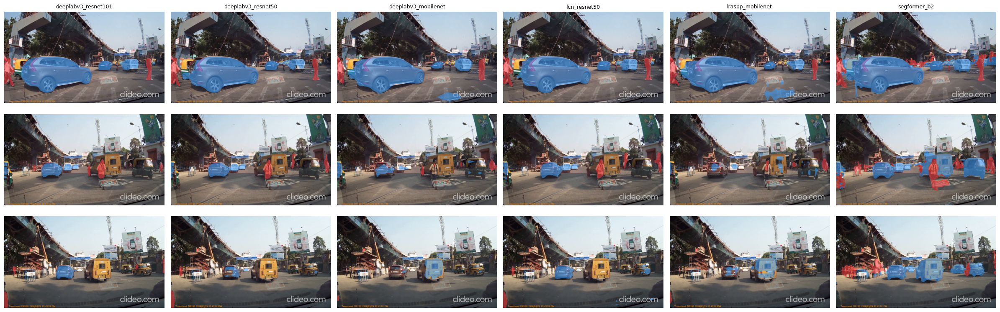

In [8]:
#visualizing the comparision
import matplotlib.pyplot as plt

PALETTE = np.array([[0, 0, 0], [255, 60, 60], [60, 160, 255]], dtype=np.uint8)

def overlay(frame, mask, alpha=0.55):
    color = PALETTE[mask]
    out = frame.copy()
    m = mask > 0
    out[m] = (frame[m] * (1 - alpha) + color[m] * alpha).astype(np.uint8)
    return out

idx = [len(frames)//4, len(frames)//2, 3*len(frames)//4]
names = list(models.keys())

fig, axes = plt.subplots(len(idx), len(names), figsize=(4*len(names), 2.6*len(idx)))
for r, fi in enumerate(idx):
    for c, n in enumerate(names):
        axes[r, c].imshow(overlay(frames[fi], predict(n, frames[fi])))
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(n, fontsize=9)
plt.tight_layout(); plt.show()

Red is person and blue is vehicle. Look for missed cars, merged vehicles, ghost masks on road signs, and ragged boundaries. This qualitative check often tells you things the numbers hide. Pick frames with tricky content (night, glare, dense traffic) by changing idx.

In [10]:
#Speed benchmark
import time, pandas as pd

def benchmark(name, frame, warmup=10, runs=50):
    x = to_tensor(frame)
    for _ in range(warmup):                 # warm-up: cuDNN autotune, lazy init
        forward_logits(name, x)
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

    times = []
    for _ in range(runs):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        forward_logits(name, x).argmax(1)
        torch.cuda.synchronize()
        times.append((time.perf_counter() - t0) * 1000)

    return {
        "model": name,
        "params_M": sum(p.numel() for p in models[name].parameters()) / 1e6,
        "latency_ms": np.mean(times),
        "latency_std": np.std(times),
        "fps": 1000 / np.mean(times),
        "peak_mem_MB": torch.cuda.max_memory_allocated() / 1e6,
    }

speed_df = pd.DataFrame([benchmark(n, frames[0]) for n in models]).set_index("model")
speed_df.round(2)

,params_M,latency_ms,latency_std,fps,peak_mem_MB
model,,,,,
deeplabv3_resnet101,61.00,215.44,6.36,4.64,857.88
deeplabv3_resnet50,42.00,157.45,5.55,6.35,857.88
deeplabv3_mobilenet,11.03,20.12,2.80,49.70,789.16
fcn_resnet50,35.32,115.95,1.29,8.62,857.88
lraspp_mobilenet,3.22,36.60,18.92,27.32,778.30
segformer_b2,27.36,67.93,13.29,14.72,1199.42


GPU calls are asynchronous, so we call torch.cuda.synchronize() before and after timing, otherwise you’d just measure kernel launch time. The warm-up runs exclude one-time startup costs. This measures pure model time (no video decoding or drawing), and the std column shows how stable the timing is.

In [11]:
# Run models over the whole video
from tqdm.auto import tqdm

masks = {n: [] for n in models}
for n in models:
    for f in tqdm(frames, desc=n):
        masks[n].append(predict(n, f))
    masks[n] = np.stack(masks[n])        # (T, H, W)

print({n: m.shape for n, m in masks.items()})

deeplabv3_resnet101:   0%|          | 0/150 [00:00<?, ?it/s]

deeplabv3_resnet50:   0%|          | 0/150 [00:00<?, ?it/s]

deeplabv3_mobilenet:   0%|          | 0/150 [00:00<?, ?it/s]

fcn_resnet50:   0%|          | 0/150 [00:00<?, ?it/s]

lraspp_mobilenet:   0%|          | 0/150 [00:00<?, ?it/s]

segformer_b2:   0%|          | 0/150 [00:00<?, ?it/s]

{'deeplabv3_resnet101': (150, 384, 672), 'deeplabv3_resnet50': (150, 384, 672), 'deeplabv3_mobilenet': (150, 384, 672), 'fcn_resnet50': (150, 384, 672), 'lraspp_mobilenet': (150, 384, 672), 'segformer_b2': (150, 384, 672)}


In [12]:
#Quality metrics (agreement with reference) and temporal stability
REF = "segformer_b2"   # change to any model; see note below

def iou(a, b, cls):
    A, B = (a == cls), (b == cls)
    union = np.logical_or(A, B).sum()
    return np.nan if union == 0 else np.logical_and(A, B).sum() / union

def agreement(pred, ref):
    res = {}
    for cls, nm in [(1, "person"), (2, "vehicle")]:
        res[f"IoU_{nm}"] = np.nanmean([iou(p, r, cls) for p, r in zip(pred, ref)])
    res["mIoU"] = np.nanmean([res["IoU_person"], res["IoU_vehicle"]])
    return res

def flicker(pred):
    # average (1 - IoU) of vehicle masks between consecutive frames; lower = steadier
    vals = [1 - iou(pred[i], pred[i+1], 2) for i in range(len(pred)-1)]
    return np.nanmean(vals)

rows = []
for n in models:
    r = agreement(masks[n], masks[REF])
    r["flicker_vehicle"] = flicker(masks[n])
    r["model"] = n
    rows.append(r)

quality_df = pd.DataFrame(rows).set_index("model")
quality_df.round(3)

,IoU_person,IoU_vehicle,mIoU,flicker_vehicle
model,,,,
deeplabv3_resnet101,0.302,0.354,0.328,0.166
deeplabv3_resnet50,0.293,0.346,0.319,0.258
deeplabv3_mobilenet,0.184,0.341,0.262,0.424
fcn_resnet50,0.291,0.450,0.371,0.233
lraspp_mobilenet,0.171,0.397,0.284,0.316
segformer_b2,1.000,1.000,1.000,0.171


Your video has no ground-truth labels, so this measures how closely each model agrees with a chosen reference. That is a proxy, not true accuracy. I default to SegFormer-B2 because it was trained on driving data, but it scores 1.0 against itself, so ignore its own row. Try REF = "deeplabv3_resnet101" too and see if the ranking changes. Flicker is the frame-to-frame instability of vehicle masks, which matters for a real dashcam pipeline. Because we use STRIDE=2, real motion contributes to flicker, but it affects all models equally, so comparisons remain valid.

In [14]:
PICK = ["deeplabv3_resnet101", "deeplabv3_mobilenet", "fcn_resnet50", "segformer_b2"]
OUT = "comparison.mp4"

def label(img, text):
    img = img.copy()
    cv2.putText(img, text, (8, 24), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
    return img

vw = cv2.VideoWriter(OUT, cv2.VideoWriter_fourcc(*"mp4v"), FPS / STRIDE,
                     (INPUT_W * 2, INPUT_H * 2))
for t, f in enumerate(frames):
    tiles = [label(overlay(f, masks[n][t]), n) for n in PICK]
    grid = np.vstack([np.hstack(tiles[:2]), np.hstack(tiles[2:])])
    vw.write(cv2.cvtColor(grid, cv2.COLOR_RGB2BGR))
vw.release()

# Re-encode to H.264 so it plays in the browser, then display
!ffmpeg -y -loglevel error -i comparison.mp4 -vcodec libx264 -pix_fmt yuv420p comparison_h264.mp4
from IPython.display import HTML
from base64 import b64encode
data = b64encode(open("comparison_h264.mp4", "rb").read()).decode()
HTML(f'<video width=800 controls><source src="data:video/mp4;base64,{data}"></video>')